# 26b — Matched-Lineage vs Cross-Lineage Recovery of the History Intervention

## Question

We test whether the generator-history intervention is recovered more strongly
when scorer and generator share model lineage.

\[
\begin{array}{c|cc}
 & \text{Qwen scorer} & \text{Falcon scorer}\\
\hline
\text{Qwen generator} & \text{matched lineage} & \text{cross lineage}\\
\text{Falcon generator} & \text{cross lineage} & \text{matched lineage}
\end{array}
\]

Models:

- Qwen generator: `Qwen/Qwen2.5-1.5B-Instruct`
- Falcon generator: `tiiuae/Falcon3-3B-Instruct`
- Qwen scorer: `Qwen/Qwen3-1.7B-Base`
- Falcon scorer: `tiiuae/Falcon3-3B-Base`

Qwen2.5/Qwen3 is called **matched-lineage**, not identical-family.

## Statistical status

This is an **exploratory mechanistic follow-up**. The hypothesis was motivated
after three of the four cells had already been observed. We therefore report
the complete crossed contrast and bootstrap uncertainty, but do not treat it as
independent confirmatory evidence.

No new text is generated. The only missing cell is Falcon-generator text scored
by Falcon3-3B-Base.

For long-range treatment effect

\[
\Delta_{g,s}
=
\frac{\Delta U_{g,s}(128)+\Delta U_{g,s}(256)}{2},
\]

define recovery strength \(R_{g,s}=-\Delta_{g,s}\). Then

\[
D_{\mathrm{lineage}}
=
\frac{
R_{Q,Q}+R_{F,F}-R_{Q,F}-R_{F,Q}
}{2}.
\]

Positive values favor matched-lineage recovery.

The secondary contrast applies the same construction to

\[
S_{g,s}
=
\Delta U_{\mathrm{long}}-\Delta U(32),
\]

again with recovery strength \(-S\).

The primary interaction uses only source IDs eligible in **all four cells**.


In [1]:
from pathlib import Path
import gc
import inspect

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

QWEN_SCORER_LABEL = "Qwen3-1.7B"
FALCON_SCORER_LABEL = "Falcon3-3B"

QWEN_GENERATOR_LABEL = "Qwen2.5-1.5B-Instruct"
FALCON_GENERATOR_LABEL = "Falcon3-3B"

FALCON_SCORER_CHECKPOINT = "tiiuae/Falcon3-3B-Base"

PREFIX_LEN = 384
CONTEXTS = [8, 32, 128, 256]
N_TARGETS = 8
TARGET_POSITIONS = np.unique(
    np.linspace(max(CONTEXTS), PREFIX_LEN - 1, N_TARGETS, dtype=int)
)

N_BOOT = 10_000
BOOT_SEED = 20260901

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32

print("ROOT:", ROOT)
print("device:", DEVICE)
print("target positions:", TARGET_POSITIONS)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
device: cuda
target positions: [256 274 292 310 328 346 364 383]


## 1. Load the three already-observed cells

In [2]:
N25A_PATH = RESULTS / "context_intervention_modern_scorer_scores.parquet"
N26_PATH = RESULTS / "modern_generator_history_intervention_scores.parquet"

assert N25A_PATH.exists(), f"Missing {N25A_PATH}"
assert N26_PATH.exists(), f"Missing {N26_PATH}"

n25a = pd.read_parquet(N25A_PATH).copy()
n26 = pd.read_parquet(N26_PATH).copy()

qwen_cells = n25a[
    (n25a["generator"] == QWEN_GENERATOR_LABEL)
    & n25a["scorer"].isin([QWEN_SCORER_LABEL, FALCON_SCORER_LABEL])
].copy()

qwen_cells = qwen_cells.rename(columns={"pair_id": "source_id"})
qwen_cells["source_id"] = qwen_cells["source_id"].astype(str)

falcon_qwen = n26[
    (n26["generator"] == FALCON_GENERATOR_LABEL)
    & (n26["scorer"] == QWEN_SCORER_LABEL)
].copy()
falcon_qwen["source_id"] = falcon_qwen["source_id"].astype(str)

print("Qwen-generator cells:")
display(
    qwen_cells.groupby("scorer")["eligible"]
    .agg(["sum","count"])
    .rename(columns={"sum":"eligible_pairs","count":"total_pairs"})
)

print("Falcon-generator × Qwen scorer:")
display(
    falcon_qwen.groupby("scorer")["eligible"]
    .agg(["sum","count"])
    .rename(columns={"sum":"eligible_pairs","count":"total_pairs"})
)


Qwen-generator cells:


,eligible_pairs,total_pairs
scorer,,
Falcon3-3B,59,60
Qwen3-1.7B,60,60


Falcon-generator × Qwen scorer:


,eligible_pairs,total_pairs
scorer,,
Qwen3-1.7B,44,60


## 2. Load the frozen Falcon intervention generations

In [3]:
FALCON_GEN_PATH = (
    RESULTS
    / "modern_generator_history_intervention"
    / "Falcon3-3B_generations.parquet"
)

assert FALCON_GEN_PATH.exists(), f"Missing {FALCON_GEN_PATH}"

falcon_generations = pd.read_parquet(FALCON_GEN_PATH).copy()
falcon_generations["source_id"] = falcon_generations["source_id"].astype(str)

display(
    falcon_generations.groupby("condition")
    .agg(n=("source_id","size"), unique_sources=("source_id","nunique"))
)

assert set(falcon_generations["condition"]) == {"full","cap32"}
assert falcon_generations["source_id"].nunique() == 60


,n,unique_sources
condition,,
cap32,60,60
full,60,60


## 3. Memory-safe Falcon3-3B-Base scorer

Falcon3-3B is close to the 8 GB GPU limit, so targets are scored one at a time.
This changes only batching, not the measured quantity.


In [4]:
def supports_logits_to_keep(model):
    try:
        return "logits_to_keep" in inspect.signature(model.forward).parameters
    except Exception:
        return False

def load_falcon_scorer():
    tok = AutoTokenizer.from_pretrained(
        FALCON_SCORER_CHECKPOINT,
        use_fast=True,
    )
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token

    try:
        model = AutoModelForCausalLM.from_pretrained(
            FALCON_SCORER_CHECKPOINT,
            dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
            low_cpu_mem_usage=True,
        )
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(
            FALCON_SCORER_CHECKPOINT,
            torch_dtype=DTYPE if DEVICE.type == "cuda" else torch.float32,
            low_cpu_mem_usage=True,
        )

    model.to(DEVICE).eval()
    return tok, model

def encode_prefix(tok, text):
    return tok(
        str(text),
        add_special_tokens=False,
        truncation=False,
    )["input_ids"][:PREFIX_LEN]

@torch.inference_mode()
def score_ids_memory_safe(model, ids):
    assert len(ids) == PREFIX_LEN
    keep = supports_logits_to_keep(model)
    losses = {k: [] for k in CONTEXTS}

    for k in CONTEXTS:
        for t in TARGET_POSITIONS:
            context = torch.tensor(
                ids[t-k:t],
                dtype=torch.long,
                device=DEVICE,
            ).unsqueeze(0)

            target = torch.tensor(
                [int(ids[t])],
                dtype=torch.long,
                device=DEVICE,
            )

            kwargs = {"input_ids": context, "use_cache": False}
            if keep:
                kwargs["logits_to_keep"] = 1

            out = model(**kwargs)
            logits = out.logits[:, -1, :].float()
            logp = torch.log_softmax(logits, dim=-1)
            nll = -logp.gather(1, target[:, None]).squeeze()

            losses[k].append(float(nll.detach().cpu()))

            del context, target, out, logits, logp, nll

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    result = {f"L_{k}": float(np.mean(losses[k])) for k in CONTEXTS}

    for k in [32,128,256]:
        result[f"U_{k}"] = result["L_8"] - result[f"L_{k}"]

    return result


## 4. Score Falcon generator with Falcon base scorer

In [5]:
FF_PATH = RESULTS / "matched_lineage_falcon_on_falcon_scores.parquet"

if FF_PATH.exists():
    print("Reusing:", FF_PATH)
    falcon_falcon = pd.read_parquet(FF_PATH)
else:
    tok, model = load_falcon_scorer()
    rows = []

    for source_id, block in tqdm(
        falcon_generations.groupby("source_id", sort=False),
        total=falcon_generations["source_id"].nunique(),
        desc="Falcon gen × Falcon scorer",
    ):
        b = block.set_index("condition")

        full_ids = encode_prefix(tok, b.loc["full", "generated_text"])
        cap_ids = encode_prefix(tok, b.loc["cap32", "generated_text"])

        eligible = (
            len(full_ids) == PREFIX_LEN
            and len(cap_ids) == PREFIX_LEN
        )

        row = {
            "generator": FALCON_GENERATOR_LABEL,
            "source_id": str(source_id),
            "scorer": FALCON_SCORER_LABEL,
            "scorer_checkpoint": FALCON_SCORER_CHECKPOINT,
            "eligible": bool(eligible),
            "full_scorer_tokens_capped": len(full_ids),
            "cap_scorer_tokens_capped": len(cap_ids),
        }

        if eligible:
            fs = score_ids_memory_safe(model, full_ids)
            cs = score_ids_memory_safe(model, cap_ids)

            for k in CONTEXTS:
                row[f"full_L_{k}"] = fs[f"L_{k}"]
                row[f"cap_L_{k}"] = cs[f"L_{k}"]

            for k in [32,128,256]:
                row[f"full_U_{k}"] = fs[f"U_{k}"]
                row[f"cap_U_{k}"] = cs[f"U_{k}"]
                row[f"delta_U_{k}"] = cs[f"U_{k}"] - fs[f"U_{k}"]

            row["delta_U_long"] = 0.5 * (
                row["delta_U_128"] + row["delta_U_256"]
            )
            row["selectivity_long_minus_short"] = (
                row["delta_U_long"] - row["delta_U_32"]
            )

        rows.append(row)

    falcon_falcon = pd.DataFrame(rows)
    falcon_falcon.to_parquet(FF_PATH, index=False)

    del model, tok
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    print("saved:", FF_PATH)

display(
    falcon_falcon.groupby("scorer")["eligible"]
    .agg(["sum","count"])
    .rename(columns={"sum":"eligible_pairs","count":"total_pairs"})
)


Falcon gen × Falcon scorer: 100%|███████████████████████████████████████████████████████████████████████| 60/60 [02:20<00:00,  2.34s/it]


saved: ../results/matched_lineage_falcon_on_falcon_scores.parquet


,eligible_pairs,total_pairs
scorer,,
Falcon3-3B,45,60


## 5. Assemble the complete 2×2 tensor

In [14]:
# ------------------------------------------------------------
# Harmonize derived intervention statistics across notebooks.
#
# Notebook 25a saved delta_U_32/128/256 and delta_U_long,
# but not the later-added selectivity statistic.
# Reconstruct derived quantities deterministically.
# ------------------------------------------------------------

for df in [qwen_cells, falcon_qwen, falcon_falcon]:

    if "delta_U_long" not in df.columns:
        df["delta_U_long"] = 0.5 * (
            df["delta_U_128"] + df["delta_U_256"]
        )

    # Recompute rather than trusting presence/absence so all cells use
    # exactly the same definition.
    df["selectivity_long_minus_short"] = (
        df["delta_U_long"]
        - df["delta_U_32"]
    )

print("Derived-statistic completeness:")

for name, df in [
    ("qwen_cells", qwen_cells),
    ("falcon_qwen", falcon_qwen),
    ("falcon_falcon", falcon_falcon),
]:
    print(
        name,
        "long NaN:",
        df["delta_U_long"].isna().sum(),
        "| selectivity NaN:",
        df["selectivity_long_minus_short"].isna().sum(),
    )

Derived-statistic completeness:
qwen_cells long NaN: 1 | selectivity NaN: 1
falcon_qwen long NaN: 16 | selectivity NaN: 16
falcon_falcon long NaN: 15 | selectivity NaN: 15


In [15]:
def keep_effect_columns(df):
    cols = [
        "generator","source_id","scorer","eligible",
        "delta_U_32","delta_U_128","delta_U_256",
        "delta_U_long","selectivity_long_minus_short",
    ]
    return df[[c for c in cols if c in df.columns]].copy()

cells_2x2 = pd.concat(
    [
        keep_effect_columns(qwen_cells),
        keep_effect_columns(falcon_qwen),
        keep_effect_columns(falcon_falcon),
    ],
    ignore_index=True,
)

dups = cells_2x2.duplicated(
    ["generator","source_id","scorer"],
    keep=False,
)
assert not dups.any(), cells_2x2.loc[dups]

display(
    cells_2x2.groupby(["generator","scorer"])["eligible"]
    .agg(["sum","count"])
    .rename(columns={"sum":"eligible_pairs","count":"total_pairs"})
    .reset_index()
)


,generator,scorer,eligible_pairs,total_pairs
0,Falcon3-3B,Falcon3-3B,45,60
1,Falcon3-3B,Qwen3-1.7B,44,60
2,Qwen2.5-1.5B-Instruct,Falcon3-3B,59,60
3,Qwen2.5-1.5B-Instruct,Qwen3-1.7B,60,60


## 6. Marginal cell estimates

In [16]:
def bootstrap_mean_ci(values, n_boot=N_BOOT, seed=BOOT_SEED):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    rng = np.random.default_rng(seed)
    n = len(x)
    boot = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot[i] = x[idx].mean()
    return (
        float(x.mean()),
        float(np.quantile(boot,.025)),
        float(np.quantile(boot,.975)),
    )

marginal_rows = []

for (generator, scorer), z in (
    cells_2x2[cells_2x2["eligible"]]
    .groupby(["generator","scorer"], sort=False)
):
    for metric in ["delta_U_long","selectivity_long_minus_short"]:
        mean, lo, hi = bootstrap_mean_ci(z[metric].to_numpy())
        marginal_rows.append({
            "generator": generator,
            "scorer": scorer,
            "metric": metric,
            "n": len(z),
            "mean": mean,
            "ci_low": lo,
            "ci_high": hi,
            "recovery_strength": -mean,
        })

marginal = pd.DataFrame(marginal_rows)
display(marginal.sort_values(["metric","generator","scorer"]))


,generator,scorer,metric,n,mean,ci_low,ci_high,recovery_strength
6,Falcon3-3B,Falcon3-3B,delta_U_long,45,-0.193659,-0.507339,0.126832,0.193659
4,Falcon3-3B,Qwen3-1.7B,delta_U_long,44,-0.368568,-0.675231,-0.051987,0.368568
2,Qwen2.5-1.5B-Instruct,Falcon3-3B,delta_U_long,59,-0.016655,-0.353712,0.321341,0.016655
0,Qwen2.5-1.5B-Instruct,Qwen3-1.7B,delta_U_long,60,-0.424938,-0.741800,-0.103209,0.424938
7,Falcon3-3B,Falcon3-3B,selectivity_long_minus_short,45,-0.431966,-0.645733,-0.226443,0.431966
5,Falcon3-3B,Qwen3-1.7B,selectivity_long_minus_short,44,-0.352842,-0.585256,-0.121575,0.352842
3,Qwen2.5-1.5B-Instruct,Falcon3-3B,selectivity_long_minus_short,59,-0.417524,-0.632623,-0.210348,0.417524
1,Qwen2.5-1.5B-Instruct,Qwen3-1.7B,selectivity_long_minus_short,60,-0.464014,-0.702293,-0.221791,0.464014


## 7. Global common-prompt subset

In [17]:
elig_wide = cells_2x2.pivot_table(
    index="source_id",
    columns=["generator","scorer"],
    values="eligible",
    aggfunc="first",
).fillna(False)

required = [
    (QWEN_GENERATOR_LABEL, QWEN_SCORER_LABEL),
    (QWEN_GENERATOR_LABEL, FALCON_SCORER_LABEL),
    (FALCON_GENERATOR_LABEL, QWEN_SCORER_LABEL),
    (FALCON_GENERATOR_LABEL, FALCON_SCORER_LABEL),
]

for col in required:
    assert col in elig_wide.columns, f"Missing cell {col}"

elig_wide["global_common"] = elig_wide[required].all(axis=1)
common_ids = set(elig_wide.index[elig_wide["global_common"]].astype(str))

print("Global common prompts:", len(common_ids), "/ 60")

common = cells_2x2[
    cells_2x2["source_id"].astype(str).isin(common_ids)
].copy()

assert len(common) == 4 * len(common_ids)
assert common["eligible"].all()


Global common prompts: 44 / 60


## 8. Source-paired matched-lineage interaction

In [18]:
def make_effect_matrix(df, metric):
    wide = df.pivot(
        index="source_id",
        columns=["generator","scorer"],
        values=metric,
    )
    R = -wide

    out = pd.DataFrame(index=R.index)
    out["R_QQ"] = R[(QWEN_GENERATOR_LABEL, QWEN_SCORER_LABEL)]
    out["R_QF"] = R[(QWEN_GENERATOR_LABEL, FALCON_SCORER_LABEL)]
    out["R_FQ"] = R[(FALCON_GENERATOR_LABEL, QWEN_SCORER_LABEL)]
    out["R_FF"] = R[(FALCON_GENERATOR_LABEL, FALCON_SCORER_LABEL)]

    out["matched_mean"] = 0.5 * (out["R_QQ"] + out["R_FF"])
    out["cross_mean"] = 0.5 * (out["R_QF"] + out["R_FQ"])
    out["D_lineage"] = out["matched_mean"] - out["cross_mean"]

    return out.reset_index()

def bootstrap_paired_mean(values, n_boot=N_BOOT, seed=BOOT_SEED):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    rng = np.random.default_rng(seed)
    n = len(x)
    boot = np.empty(n_boot)

    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot[i] = x[idx].mean()

    est = float(x.mean())
    lo = float(np.quantile(boot,.025))
    hi = float(np.quantile(boot,.975))
    tail = float(
        min(
            1.0,
            2 * min(np.mean(boot <= 0), np.mean(boot >= 0))
        )
    )
    return est, lo, hi, tail

interaction_rows = []
interaction_tables = {}

for metric in ["delta_U_long","selectivity_long_minus_short"]:
    tab = make_effect_matrix(common, metric)
    interaction_tables[metric] = tab

    est, lo, hi, tail = bootstrap_paired_mean(tab["D_lineage"].to_numpy())

    interaction_rows.append({
        "metric": metric,
        "n_global_common": len(tab),
        "matched_recovery_mean": tab["matched_mean"].mean(),
        "cross_recovery_mean": tab["cross_mean"].mean(),
        "matched_minus_cross": est,
        "ci_low": lo,
        "ci_high": hi,
        "exploratory_bootstrap_tail_area": tail,
    })

interaction = pd.DataFrame(interaction_rows)
display(interaction)


,metric,n_global_common,matched_recovery_mean,cross_recovery_mean,matched_minus_cross,ci_low,ci_high,exploratory_bootstrap_tail_area
0,delta_U_long,44,0.213713,0.236963,-0.023250,-0.406143,0.340943,0.9030
1,selectivity_long_minus_short,44,0.361520,0.402444,-0.040924,-0.212989,0.130432,0.6254


## 9. Common-prompt 2×2 matrices

In [19]:
matrix_rows = []

for metric in ["delta_U_long","selectivity_long_minus_short"]:
    for (generator, scorer), z in common.groupby(
        ["generator","scorer"], sort=False
    ):
        matrix_rows.append({
            "metric": metric,
            "generator": generator,
            "scorer": scorer,
            "n": len(z),
            "delta_mean": z[metric].mean(),
            "recovery_mean": -z[metric].mean(),
        })

matrix_df = pd.DataFrame(matrix_rows)

for metric in ["delta_U_long","selectivity_long_minus_short"]:
    print("\n", metric)
    display(
        matrix_df[matrix_df["metric"] == metric]
        .pivot(index="scorer", columns="generator", values="recovery_mean")
    )



 delta_U_long


generator,Falcon3-3B,Qwen2.5-1.5B-Instruct
scorer,,
Falcon3-3B,0.168662,0.105359
Qwen3-1.7B,0.368568,0.258765



 selectivity_long_minus_short


generator,Falcon3-3B,Qwen2.5-1.5B-Instruct
scorer,,
Falcon3-3B,0.412438,0.452046
Qwen3-1.7B,0.352842,0.310602


## 10. Within-generator matched-vs-cross contrasts

These show whether any aggregate diagonal advantage is supported in both
generator families or driven by only one.


In [20]:
within_rows = []

for metric, tab in interaction_tables.items():
    contrasts = {
        "Qwen lineage": tab["R_QQ"] - tab["R_QF"],
        "Falcon lineage": tab["R_FF"] - tab["R_FQ"],
    }

    for lineage, values in contrasts.items():
        est, lo, hi, tail = bootstrap_paired_mean(values.to_numpy())

        within_rows.append({
            "metric": metric,
            "generator_lineage": lineage,
            "n": len(values),
            "matched_minus_cross_recovery": est,
            "ci_low": lo,
            "ci_high": hi,
            "exploratory_bootstrap_tail_area": tail,
        })

within = pd.DataFrame(within_rows)
display(within)


,metric,generator_lineage,n,matched_minus_cross_recovery,ci_low,ci_high,exploratory_bootstrap_tail_area
0,delta_U_long,Qwen lineage,44,0.153406,-0.422135,0.712308,0.5978
1,delta_U_long,Falcon lineage,44,-0.199905,-0.646088,0.267836,0.3904
2,selectivity_long_minus_short,Qwen lineage,44,-0.141444,-0.456269,0.181861,0.3874
3,selectivity_long_minus_short,Falcon lineage,44,0.059595,-0.245823,0.360315,0.6946


## 11. Descriptive recovery matrix figure

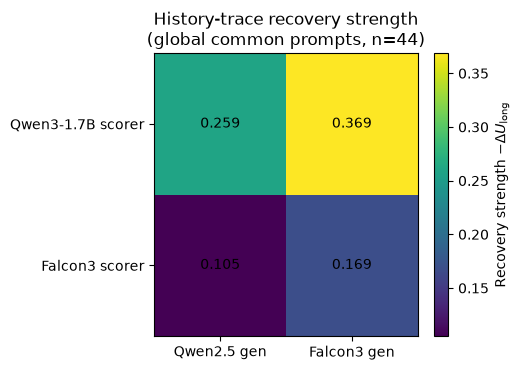

saved: ../figures/matched_lineage_intervention_matrix.pdf
saved: ../figures/matched_lineage_intervention_matrix.png


In [21]:
z = matrix_df[matrix_df["metric"] == "delta_U_long"].copy()

pivot = z.pivot(
    index="scorer",
    columns="generator",
    values="recovery_mean",
).loc[
    [QWEN_SCORER_LABEL, FALCON_SCORER_LABEL],
    [QWEN_GENERATOR_LABEL, FALCON_GENERATOR_LABEL],
]

fig, ax = plt.subplots(figsize=(5.2,3.8))
im = ax.imshow(pivot.to_numpy(), aspect="auto")

ax.set_xticks([0,1])
ax.set_xticklabels(["Qwen2.5 gen","Falcon3 gen"])
ax.set_yticks([0,1])
ax.set_yticklabels(["Qwen3-1.7B scorer","Falcon3 scorer"])

for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{pivot.iloc[i,j]:.3f}", ha="center", va="center")

ax.set_title(
    "History-trace recovery strength\n"
    f"(global common prompts, n={len(common_ids)})"
)
fig.colorbar(im, ax=ax, label=r"Recovery strength $-\Delta U_{\mathrm{long}}$")
fig.tight_layout()

FIG_PDF = FIGURES / "matched_lineage_intervention_matrix.pdf"
FIG_PNG = FIGURES / "matched_lineage_intervention_matrix.png"

fig.savefig(FIG_PDF, bbox_inches="tight")
fig.savefig(FIG_PNG, dpi=250, bbox_inches="tight")
plt.show()

print("saved:", FIG_PDF)
print("saved:", FIG_PNG)


## 12. Save outputs

In [22]:
INTERACTION_PATH = RESULTS / "matched_lineage_intervention_interaction.csv"
WITHIN_PATH = RESULTS / "matched_lineage_intervention_within_generator.csv"
MATRIX_PATH = RESULTS / "matched_lineage_intervention_common_matrix.csv"

interaction.to_csv(INTERACTION_PATH, index=False)
within.to_csv(WITHIN_PATH, index=False)
matrix_df.to_csv(MATRIX_PATH, index=False)

for metric, tab in interaction_tables.items():
    tab.to_csv(
        RESULTS / f"matched_lineage_intervention_pairwise_{metric}.csv",
        index=False,
    )

print("saved:")
for p in [
    FF_PATH,
    INTERACTION_PATH,
    WITHIN_PATH,
    MATRIX_PATH,
    FIG_PDF,
    FIG_PNG,
]:
    print(" ", p)


saved:
  ../results/matched_lineage_falcon_on_falcon_scores.parquet
  ../results/matched_lineage_intervention_interaction.csv
  ../results/matched_lineage_intervention_within_generator.csv
  ../results/matched_lineage_intervention_common_matrix.csv
  ../figures/matched_lineage_intervention_matrix.pdf
  ../figures/matched_lineage_intervention_matrix.png


## 13. Interpretation gate

Because three cells were known before this hypothesis was proposed, this branch
is exploratory.

- **Positive interaction, both within-generator contrasts positive:** consistent
  with a matched-lineage observation affinity.
- **Positive aggregate but only one lineage positive:** asymmetric
  scorer-generator interaction; do not claim general lineage matching.
- **Null interaction:** scorer dependence is not explained by simple lineage.
- **Negative interaction:** the simple matched-lineage explanation is rejected.

If the pending Llama generator is later added, a Llama-family scorer and the
extension criterion should be fixed **before inspecting Llama intervention
results** if we want a cleaner independent test of the lineage hypothesis.
